# ML_500 — Phase 2 EDA gate (500-profile structural sweep)

**Purpose**: decide **GO / NO-GO** for the model-recommender before any modeling. The dataset is `Output/sweep_ml.parquet` — 500 LHS profiles x 135 models x 6 volumes x 7 server counts = 2,835,000 structural rows with 60 per-query unit-cost columns.

Gate questions:
1. **Coverage** — are all 18 sampled dims evenly (log-)spread? Where are the gaps / how far are the corners?
2. **Target shape & the log question** — how skewed are the costs; how much does `expm1` amplify log-space error; what objective does the mean-variance relation suggest?
3. **Signal** — after removing the known (model, volume, servers) grid, do the schema features still move cost (the part a model must learn)?
4. **Ranking signal** — does the *best* model actually change across configs and workloads (is there anything to recommend)?
5. **Outliers** — are S00-type extremes real corner configs or artifacts?
6. **Verdict** — computed checklist + GO/NO-GO, saved to `notebooks/eda_summary.json`.

In [1]:
import json, re, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 90

DATASET = ROOT / "Output" / "sweep_ml.parquet"
schema = pq.ParquetFile(DATASET).schema_arrow.names

KEYS   = ["profile_id", "xml_file", "data_volume", "servers"]
TOTALS = ["total_time_cost", "total_environmental_cost", "total_financial_cost"]
SEL    = sorted(c for c in schema if c.startswith("sel_"))
IDX    = sorted(c for c in schema if c.startswith("idx_"))
COUNTS = ["customer_count", "order_count"]
STRUCT = SEL + IDX + COUNTS
UNIT_T = sorted((c for c in schema if re.match(r"q\d+_time_cost$", c)),
                key=lambda c: int(c.split("_")[0][1:]))
UNIT_E = [c.replace("_time_", "_env_") for c in UNIT_T]
UNIT_F = [c.replace("_time_", "_fin_") for c in UNIT_T]
UNITS  = UNIT_T + UNIT_E + UNIT_F
NQ = len(UNIT_T)

df = pd.read_parquet(DATASET, columns=KEYS + STRUCT + TOTALS + UNITS)
for c in TOTALS + UNITS + SEL + COUNTS + ["data_volume", "servers"]:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype("float32")
df["xml_file"] = df["xml_file"].astype("category")
df["profile_id"] = df["profile_id"].astype("category")
summary = {}
print(f"{df.shape[0]:,} rows x {df.shape[1]} cols, {NQ} queries, "
      f"{df.memory_usage(deep=True).sum()/1e9:.2f} GB in RAM")

2,835,000 rows x 85 cols, 20 queries, 1.04 GB in RAM


In [2]:
# --- Integrity: is the grid complete and clean? ---
n_prof = df["profile_id"].nunique(); n_mod = df["xml_file"].nunique()
n_vol = df["data_volume"].nunique(); n_srv = df["servers"].nunique()
expected = n_prof * n_mod * n_vol * n_srv
grid_ok = len(df) == expected
dupes = int(df.duplicated(subset=KEYS).sum())
tot_nulls = int(df[TOTALS].isna().sum().sum())
tot_nonpos = int((df[TOTALS] <= 0).sum().sum())
unit_nan_share = float(df[UNITS].isna().mean().mean())
unit_zero_share = float((df[UNITS] == 0).mean().mean())
models_per_prof = df.groupby("profile_id", observed=True)["xml_file"].nunique()

print(f"grid: {n_prof} profiles x {n_mod} models x {n_vol} volumes x {n_srv} servers = {expected:,}"
      f" -> rows {len(df):,}  [{'OK' if grid_ok else 'MISMATCH'}]")
print(f"duplicate keys: {dupes}   total-cost nulls: {tot_nulls}   total-cost non-positive: {tot_nonpos}")
print(f"models/profile: min={models_per_prof.min()} max={models_per_prof.max()}")
print(f"unit-cost cells: NaN {unit_nan_share:.2%}, zero {unit_zero_share:.2%}")
summary["integrity"] = {"grid_complete": bool(grid_ok), "dupes": dupes,
                         "total_nulls": tot_nulls, "total_nonpos": tot_nonpos,
                         "unit_nan_share": unit_nan_share, "unit_zero_share": unit_zero_share}

grid: 500 profiles x 135 models x 6 volumes x 7 servers = 2,835,000 -> rows 2,835,000  [OK]
duplicate keys: 0   total-cost nulls: 0   total-cost non-positive: 0
models/profile: min=135 max=135
unit-cost cells: NaN 0.00%, zero 0.00%


## 1 · Coverage of the 18 sampled dimensions
One row per profile (the 18 dims are constant within a profile). Continuous dims are viewed in log10; index flags as 0/1 balance. Then: nearest-neighbour distances in the normalized 18-dim space to find under-sampled regions, and distance from the 4 extreme corners (the configs that broke the last model).

500 profiles


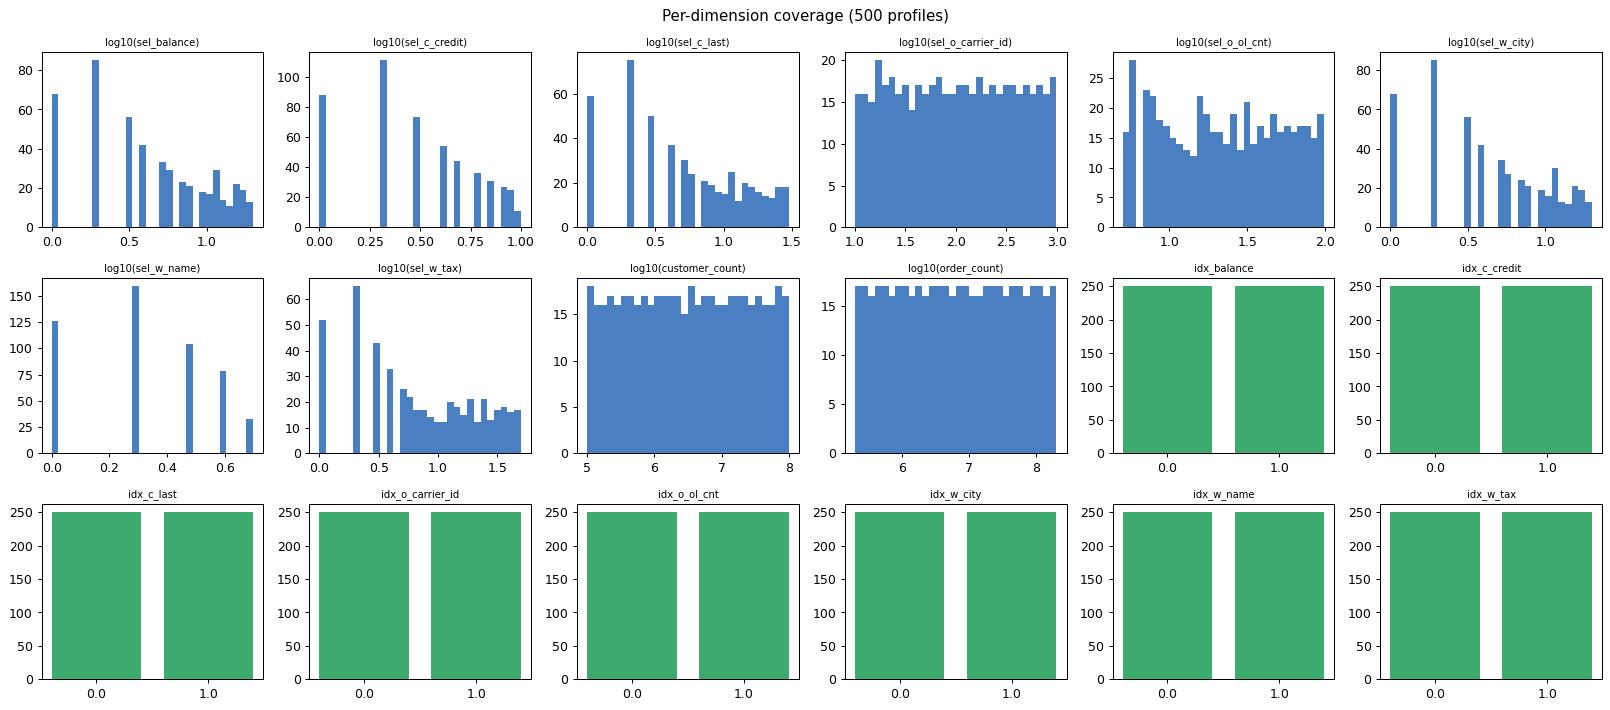

,dim,cfg_lo,cfg_hi,obs_lo,obs_hi,log_span_covered
0,sel_balance,1.0,20.0,1.0,20.0,1.000
1,sel_c_credit,1.0,10.0,1.0,10.0,1.000
2,sel_c_last,1.0,30.0,1.0,30.0,1.000
3,sel_o_carrier_id,10.0,1000.0,10.0,994.0,0.999
4,sel_o_ol_cnt,5.0,100.0,5.0,99.0,0.997
5,sel_w_city,1.0,20.0,1.0,20.0,1.000
6,sel_w_name,1.0,5.0,1.0,5.0,1.000
7,sel_w_tax,1.0,50.0,1.0,50.0,1.000
8,customer_count,100000.0,100000000.0,100792.0,98915184.0,0.997
9,order_count,200000.0,200000000.0,201301.0,199897264.0,0.999


index-flag ON share per dim: {'idx_balance': 0.5, 'idx_c_credit': 0.5, 'idx_c_last': 0.5, 'idx_o_carrier_id': 0.5, 'idx_o_ol_cnt': 0.5, 'idx_w_city': 0.5, 'idx_w_name': 0.5, 'idx_w_tax': 0.5}


In [3]:
prof = df.groupby("profile_id", observed=True)[STRUCT].first().astype(float)
print(f"{len(prof)} profiles")

fig, axes = plt.subplots(3, 6, figsize=(18, 8)); axes = axes.ravel()
for i, c in enumerate(SEL + COUNTS):
    axes[i].hist(np.log10(prof[c]), bins=30, color="#4A7FC1")
    axes[i].set_title(f"log10({c})", fontsize=8)
for j, c in enumerate(IDX):
    vc = prof[c].value_counts().sort_index()
    axes[10 + j].bar(vc.index.astype(str), vc.values, color="#3DAA6E")
    axes[10 + j].set_title(c, fontsize=8)
plt.suptitle("Per-dimension coverage (500 profiles)"); plt.tight_layout(); plt.show()

# Observed span vs the configured LHS ranges (log-space fraction covered)
try:
    from scripts.sweep_profiles import SELECTIVITY_RANGES, CUSTOMER_RANGE, ORDER_RANGE
    rows = []
    rng_map = {f"sel_{k}": v for k, v in SELECTIVITY_RANGES.items()}
    rng_map["customer_count"] = CUSTOMER_RANGE
    rng_map["order_count"] = ORDER_RANGE
    for c in SEL + COUNTS:
        lo, hi = map(float, rng_map[c])
        omin, omax = prof[c].min(), prof[c].max()
        cov = (np.log(omax) - np.log(omin)) / max(np.log(hi) - np.log(lo), 1e-9)
        rows.append({"dim": c, "cfg_lo": lo, "cfg_hi": hi, "obs_lo": omin, "obs_hi": omax,
                     "log_span_covered": round(cov, 3)})
    cov_tbl = pd.DataFrame(rows)
    display(cov_tbl)
    summary["coverage_min_span"] = float(cov_tbl["log_span_covered"].min())
except Exception as e:
    print("range table skipped:", e)
    summary["coverage_min_span"] = None
idx_balance = prof[IDX].mean()
summary["idx_flag_balance"] = {k: round(float(v), 3) for k, v in idx_balance.items()}
print("index-flag ON share per dim:", dict(summary["idx_flag_balance"]))

NN distance: median=1.177  p90=1.391  max=1.673  (max/median = 1.42)


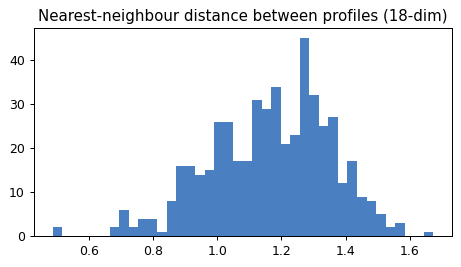

  corner 'all-min sel/counts + all-indexed': nearest sample at 1.657 (~1.4x median NN gap)
  corner 'all-min sel/counts + no-index': nearest sample at 1.501 (~1.3x median NN gap)
  corner 'all-max sel/counts + all-indexed': nearest sample at 1.582 (~1.3x median NN gap)
  corner 'all-max sel/counts + no-index': nearest sample at 1.462 (~1.2x median NN gap)


In [4]:
# --- Nearest-neighbour gaps + corner anchors, in [0,1]-normalized 18-dim space ---
from scipy.spatial.distance import cdist

Z = pd.DataFrame(index=prof.index)
for c in SEL + COUNTS:
    v = np.log10(prof[c])
    Z[c] = (v - v.min()) / max(v.max() - v.min(), 1e-9)
for c in IDX:
    Z[c] = prof[c]
X = Z.to_numpy(float)

D = cdist(X, X); np.fill_diagonal(D, np.inf)
nn = D.min(axis=1)
nn_ratio = float(nn.max() / np.median(nn))
print(f"NN distance: median={np.median(nn):.3f}  p90={np.quantile(nn,.9):.3f}  "
      f"max={nn.max():.3f}  (max/median = {nn_ratio:.2f})")

plt.figure(figsize=(6, 3)); plt.hist(nn, bins=40, color="#4A7FC1")
plt.title("Nearest-neighbour distance between profiles (18-dim)"); plt.show()

# The 4 extreme corners RECOMMENDER_NOTES calls out (anchors not yet injected)
nc, ni = len(SEL + COUNTS), len(IDX)
corners = {
    "all-min sel/counts + all-indexed": np.r_[np.zeros(nc), np.ones(ni)],
    "all-min sel/counts + no-index":    np.r_[np.zeros(nc), np.zeros(ni)],
    "all-max sel/counts + all-indexed": np.r_[np.ones(nc),  np.ones(ni)],
    "all-max sel/counts + no-index":    np.r_[np.ones(nc),  np.zeros(ni)],
}
corner_gaps = {}
for name, vec in corners.items():
    d = float(np.linalg.norm(X - vec, axis=1).min())
    corner_gaps[name] = round(d, 3)
    print(f"  corner '{name}': nearest sample at {d:.3f} (~{d/np.median(nn):.1f}x median NN gap)")
summary["nn_median"] = float(np.median(nn)); summary["nn_max_ratio"] = nn_ratio
summary["corner_gaps"] = corner_gaps

## 2 · Target shape & the log question
The last model trained on `log1p(cost)` and looked good in log space, but `expm1` amplified small log errors into large raw errors. Here: how skewed the targets are, exactly how much a given log error costs in raw %, and what the mean-variance relation says about better objectives (Tweedie/Gamma).

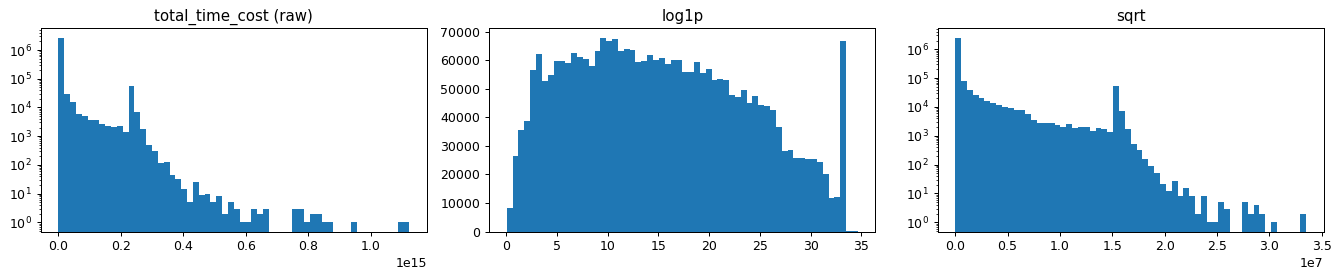

,target,skew_raw,skew_log1p,p50,p99,max,zeros%
0,total_time_cost,5.7,0.25,2.426262e+06,2.320312e+14,1.124322e+15,0.0
1,total_environmental_cost,26.9,0.38,1.032916e+06,1.364137e+13,3.935128e+14,0.0
2,total_financial_cost,5.6,0.33,8.045823e+12,4.381109e+21,4.381846e+21,0.0
3,q1_time_cost,3.7,3.70,5.109480e-05,1.020274e-03,7.825493e-03,0.0
4,q2_time_cost,2.3,2.32,1.101236e-04,3.701786e-03,7.905506e-03,0.0
5,q3_time_cost,7.2,7.15,2.802800e-05,1.593112e-03,7.365450e-03,0.0
6,q4_time_cost,5.6,0.88,5.159760e+01,2.310419e+11,2.549345e+11,0.0
7,q5_time_cost,259.2,17.67,5.616880e-05,6.666723e-01,4.900976e+05,0.0


In [5]:
from scipy.stats import skew

y = df["total_time_cost"].to_numpy(float)
y = y[np.isfinite(y) & (y > 0)]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
ax[0].hist(y, bins=60); ax[0].set_yscale("log"); ax[0].set_title("total_time_cost (raw)")
ax[1].hist(np.log1p(y), bins=60); ax[1].set_title("log1p")
ax[2].hist(np.sqrt(y), bins=60); ax[2].set_yscale("log"); ax[2].set_title("sqrt")
plt.tight_layout(); plt.show()

rows = []
for c in TOTALS + UNIT_T[:5]:
    v = df[c].dropna().to_numpy(float)
    v = v[v >= 0]
    rows.append({"target": c, "skew_raw": round(float(skew(v)), 1),
                 "skew_log1p": round(float(skew(np.log1p(v))), 2),
                 "p50": float(np.median(v)), "p99": float(np.quantile(v, .99)),
                 "max": float(v.max()), "zeros%": round(100 * float((v == 0).mean()), 2)})
shape_tbl = pd.DataFrame(rows)
display(shape_tbl)
summary["skew_raw_total_time"] = float(shape_tbl.loc[0, "skew_raw"])
summary["skew_log1p_total_time"] = float(shape_tbl.loc[0, "skew_log1p"])

In [6]:
# --- Quantify the expm1 amplification: fixed log-space error -> raw % error ---
rng = np.random.default_rng(0)
samp = rng.choice(y, size=min(200_000, y.size), replace=False)
rows = []
for sigma in [0.1, 0.2, 0.3, 0.45, 0.6]:
    e = rng.normal(0, sigma, samp.size)
    pred = np.expm1(np.log1p(samp) + e)
    rel = np.abs(pred - samp) / samp
    rows.append({"log_error_sigma": sigma,
                 "raw_rel_err_p50": round(float(np.median(rel)), 3),
                 "raw_rel_err_p90": round(float(np.quantile(rel, .9)), 3),
                 "raw_rel_err_p99": round(float(np.quantile(rel, .99)), 3)})
amp_tbl = pd.DataFrame(rows)
display(amp_tbl)
print("Reading: the failed model's ~0.6 log-MAE row shows why raw errors reached 1.8x+;"
      " even sigma=0.3 already implies large raw error at p90.")
summary["amplification"] = amp_tbl.to_dict("records")

,log_error_sigma,raw_rel_err_p50,raw_rel_err_p90,raw_rel_err_p99
0,0.10,0.068,0.168,0.279
1,0.20,0.136,0.336,0.617
2,0.30,0.203,0.508,1.045
3,0.45,0.301,0.801,1.903
4,0.60,0.391,1.182,3.160


Reading: the failed model's ~0.6 log-MAE row shows why raw errors reached 1.8x+; even sigma=0.3 already implies large raw error at p90.


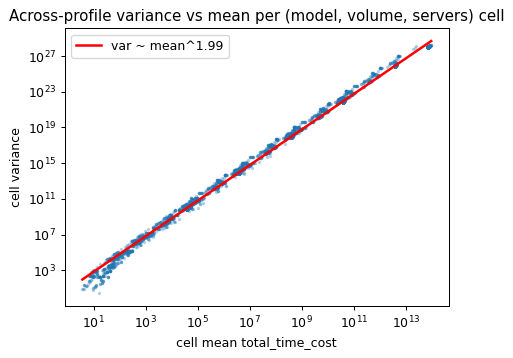

Tweedie power estimate p = 1.99


In [7]:
# --- Mean-variance relation across profiles (Tweedie power estimate) ---
# Within each (model, volume, servers) cell the 500 profiles give a distribution;
# var ~ mean^p suggests the GLM family: p~1 Poisson-like, 1<p<2 Tweedie, p~2 Gamma (const CV).
g = df.groupby(["xml_file", "data_volume", "servers"], observed=True)["total_time_cost"]
mv = pd.DataFrame({"mean": g.mean(), "var": g.var()}).dropna()
mv = mv[(mv["mean"] > 0) & (mv["var"] > 0)]
slope, intercept = np.polyfit(np.log(mv["mean"]), np.log(mv["var"]), 1)
plt.figure(figsize=(5.5, 4))
plt.scatter(mv["mean"], mv["var"], s=3, alpha=.25)
xs = np.geomspace(mv["mean"].min(), mv["mean"].max(), 50)
plt.plot(xs, np.exp(intercept) * xs**slope, "r-", lw=2, label=f"var ~ mean^{slope:.2f}")
plt.xscale("log"); plt.yscale("log"); plt.legend()
plt.title("Across-profile variance vs mean per (model, volume, servers) cell")
plt.xlabel("cell mean total_time_cost"); plt.ylabel("cell variance"); plt.show()
print(f"Tweedie power estimate p = {slope:.2f}")
summary["tweedie_power"] = round(float(slope), 2)

## 3 · Feature → cost signal (the learnable residual)
`data_volume`, `servers`, and the model identity explain most raw variance — but those are grid keys, not learned features. The recommender must learn what the **schema config** (selectivities, index flags, counts) does *on top of* that grid. So the signal check is on the **residual**: `log1p(cost)` minus its (model, volume, servers) group mean.

grid (model, volume, servers) explains 85.4% of log-cost variance; residual std = 3.273 log-units -> that's what the features must explain


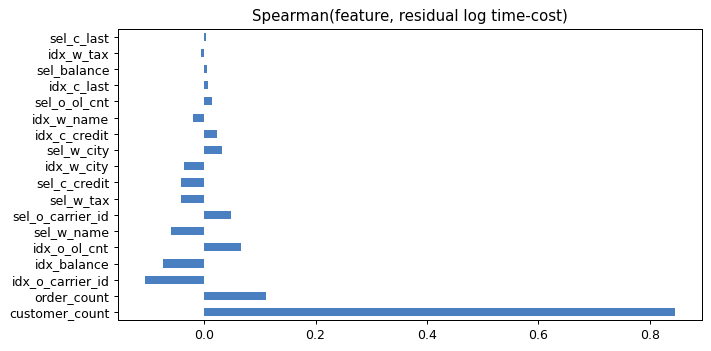

,spearman_vs_residual
customer_count,0.846
order_count,0.111
idx_o_carrier_id,-0.107
idx_balance,-0.074
idx_o_ol_cnt,0.067
sel_w_name,-0.059
sel_o_carrier_id,0.048
sel_w_tax,-0.042
sel_c_credit,-0.041
idx_w_city,-0.037


top mutual information vs residual:


,MI
customer_count,1.3889
sel_o_carrier_id,1.0211
order_count,0.8946
sel_o_ol_cnt,0.5922
sel_w_tax,0.3722
sel_c_last,0.2763
sel_balance,0.2093
sel_w_city,0.2075


In [8]:
ln = pd.Series(np.log1p(df["total_time_cost"].to_numpy(float)), index=df.index)
base = ln.groupby([df["xml_file"], df["data_volume"], df["servers"]], observed=True).transform("mean")
df["_resid"] = (ln - base).astype("float32")
grid_r2 = float(1 - df["_resid"].var() / ln.var())
print(f"grid (model, volume, servers) explains {grid_r2:.1%} of log-cost variance;"
      f" residual std = {df['_resid'].std():.3f} log-units -> that's what the features must explain")

samp = df.sample(300_000, random_state=0)
feat = samp[STRUCT].astype(float).copy()
for c in SEL + COUNTS:
    feat[c] = np.log10(feat[c])
rho = pd.concat([feat, samp[["_resid"]]], axis=1).corr(method="spearman")["_resid"].drop("_resid")
rho = rho.sort_values(key=np.abs, ascending=False)
plt.figure(figsize=(8, 4)); rho.plot.barh(color="#4A7FC1")
plt.title("Spearman(feature, residual log time-cost)"); plt.tight_layout(); plt.show()
display(rho.round(3).to_frame("spearman_vs_residual"))

from sklearn.feature_selection import mutual_info_regression
ms = samp.sample(50_000, random_state=0)
mi = mutual_info_regression(ms[STRUCT].astype(float).fillna(0), ms["_resid"], random_state=0)
mi_s = pd.Series(mi, index=STRUCT).sort_values(ascending=False)
print("top mutual information vs residual:")
display(mi_s.head(8).round(4).to_frame("MI"))
summary["grid_explained_var"] = round(grid_r2, 4)
summary["residual_std_log"] = round(float(df["_resid"].std()), 4)
summary["top_spearman"] = {k: round(float(v), 3) for k, v in rho.head(5).items()}
summary["max_abs_spearman"] = float(rho.abs().max())
summary["max_mi"] = float(mi_s.max())

## 4 · Ranking signal — is there anything to recommend?
Composite = eq14-style within-config normalization (log1p min-max per metric over the 135 models of one `(profile, volume, servers)` config), averaged over time/env/financial. Questions: does the winner vary across configs? how close is #2 (margin)? are orderings consistent (learnable) but not constant (trivial)? does the winner respond to the query workload?

21,000 configs; distinct winning models: 25
top winner Merge_c_ID_c_o_ID/Merge_w_ID_w_c_ID wins 28.8% of configs
composite margin best->2nd: p25=0.0030 p50=0.0145 p90=0.0998


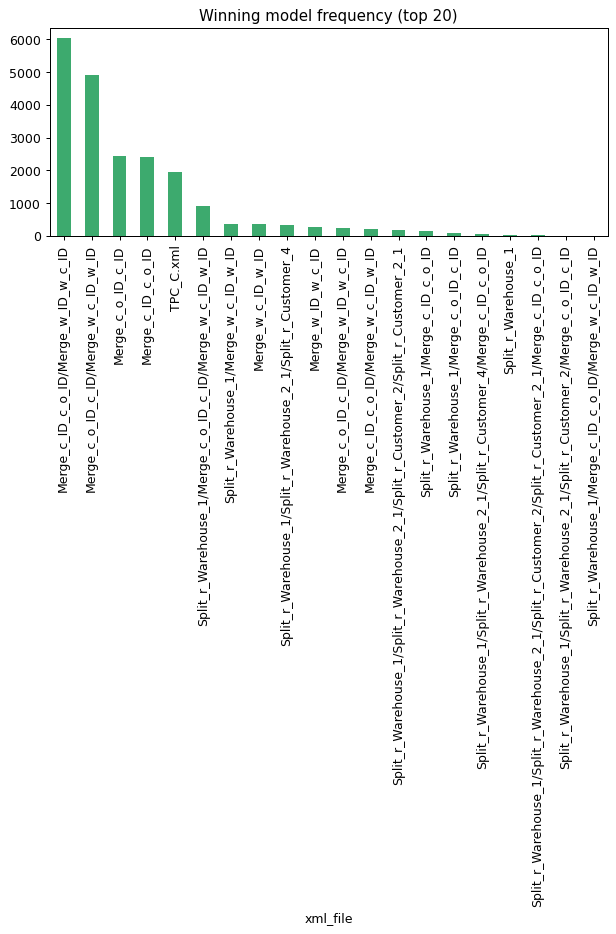

mean pairwise rank correlation between configs: 0.785 (1.0 would mean the ordering never changes -> nothing to learn)


In [9]:
key = ["profile_id", "data_volume", "servers"]
comp = np.zeros(len(df))
for m in TOTALS:
    lnm = pd.Series(np.log1p(df[m].to_numpy(float)), index=df.index)
    grp = lnm.groupby([df[k] for k in key], observed=True)
    mn, mx = grp.transform("min"), grp.transform("max")
    r = (lnm - mn) / (mx - mn).replace(0, np.nan)
    comp += r.fillna(0).to_numpy() / len(TOTALS)
df["composite"] = comp.astype("float32")

d2 = df[key + ["xml_file", "composite"]].sort_values("composite")
g2 = d2.groupby(key, observed=True)
best = g2.first()
top2 = g2.head(2).groupby(key, observed=True)["composite"].agg(["min", "max"])
margin = top2["max"] - top2["min"]

win_counts = best["xml_file"].value_counts()
win_counts = win_counts[win_counts > 0]
n_cfg = len(best)
print(f"{n_cfg:,} configs; distinct winning models: {len(win_counts)}")
print(f"top winner {win_counts.index[0]} wins {win_counts.iloc[0]/n_cfg:.1%} of configs")
print(f"composite margin best->2nd: p25={margin.quantile(.25):.4f} "
      f"p50={margin.median():.4f} p90={margin.quantile(.9):.4f}")
plt.figure(figsize=(8, 3))
win_counts.head(20).plot.bar(color="#3DAA6E")
plt.title("Winning model frequency (top 20)"); plt.tight_layout(); plt.show()

# Ordering consistency between configs: spearman of the 135-model rank vectors
df["_cfg"] = (df["profile_id"].astype(str) + "|" + df["data_volume"].astype(int).astype(str)
              + "|" + df["servers"].astype(int).astype(str))
rng = np.random.default_rng(2)
cfg_ids = rng.choice(df["_cfg"].unique(), size=100, replace=False)
P = (df[df["_cfg"].isin(set(cfg_ids))]
     .pivot_table(index="_cfg", columns="xml_file", values="composite", observed=True))
R = P.rank(axis=1).to_numpy()
C = np.corrcoef(R)
mean_rank_corr = float(C[np.triu_indices_from(C, k=1)].mean())
print(f"mean pairwise rank correlation between configs: {mean_rank_corr:.3f} "
      "(1.0 would mean the ordering never changes -> nothing to learn)")
summary["distinct_winners"] = int(len(win_counts))
summary["top_winner_share"] = round(float(win_counts.iloc[0] / n_cfg), 3)
summary["margin_p50"] = round(float(margin.median()), 4)
summary["mean_rank_corr_between_configs"] = round(mean_rank_corr, 3)

In [10]:
# --- Does the winner respond to the workload? (frequency is closed-form: total = U @ f) ---
# Reconstruction was verified exactly for time cost (validate_scenario_dataset); env/fin
# are treated the same way here as an approximation for the composite.
try:
    from lib.constants import DEFAULT_QUERY_FREQUENCIES
    f0 = np.array([DEFAULT_QUERY_FREQUENCIES.get(f"q{i}", 1) for i in range(1, NQ + 1)], float)
except Exception:
    f0 = np.ones(NQ)

def _norm01(v):
    v = np.log1p(v); span = v.max() - v.min()
    return (v - v.min()) / span if span > 0 else np.zeros_like(v)

rng = np.random.default_rng(3)
cfg_sample = rng.choice(df["_cfg"].unique(), size=30, replace=False)
variety, variety_time = [], []
for cfg in cfg_sample:
    sub = df[df["_cfg"] == cfg]
    Ut = np.nan_to_num(sub[UNIT_T].to_numpy(float))
    Ue = np.nan_to_num(sub[UNIT_E].to_numpy(float))
    Uf = np.nan_to_num(sub[UNIT_F].to_numpy(float))
    models = sub["xml_file"].to_numpy()
    wins, wins_t = set(), set()
    for _ in range(25):
        f = f0 * np.exp(rng.uniform(np.log(0.2), np.log(5.0), NQ))
        tt, ee, ff = Ut @ f, Ue @ f, Uf @ f
        cmp_ = (_norm01(tt) + _norm01(ee) + _norm01(ff)) / 3
        wins.add(models[np.argmin(cmp_)])
        wins_t.add(models[np.argmin(tt)])
    variety.append(len(wins)); variety_time.append(len(wins_t))
print(f"distinct composite winners per config across 25 workloads: "
      f"mean={np.mean(variety):.1f}  max={max(variety)}")
print(f"distinct time-only winners per config across 25 workloads:  "
      f"mean={np.mean(variety_time):.1f}  max={max(variety_time)}")
summary["workload_winner_variety_mean"] = round(float(np.mean(variety)), 2)

distinct composite winners per config across 25 workloads: mean=2.1  max=5
distinct time-only winners per config across 25 workloads:  mean=2.1  max=5


## 5 · Outliers — real corners or artifacts?
Profile-level median cost is ~log-normal (raw skew 5.7 vs log1p skew 0.25), so outlier detection must run on the **log scale** — a raw-scale MAD test would flag the entire upper tail of a log-normal by construction (a first draft of this cell did exactly that and mislabeled 30% of profiles as outliers). Flagged profiles are then checked against sampling-range edges. As a driver sanity check, a linear model on the log-dims should explain most of the profile cost level if the extremes are feature-driven rather than artifacts.

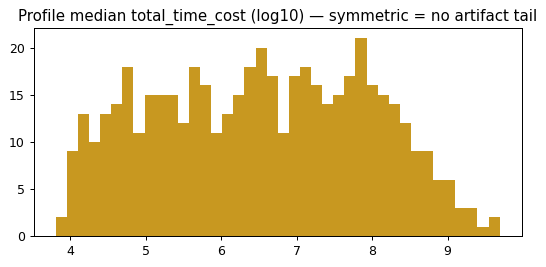

log10(profile median): skew=0.006, range 3.81 -> 9.69
profiles flagged |robust z| > 5 (log scale): 0

linear model (log dims -> log10 profile cost): R2 = 0.963
top drivers:


,coef
log_customer_count,1.571
idx_o_carrier_id,-0.328
idx_w_city,-0.236
log_order_count,0.227
log_sel_o_carrier_id,0.174
log_sel_c_last,0.115


In [11]:
pm = df.groupby("profile_id", observed=True)["total_time_cost"].median()
lpm = np.log10(pm)
mad = float((lpm - lpm.median()).abs().median())
rz = 0.6745 * (lpm - lpm.median()) / max(mad, 1e-12)
flagged = rz[rz.abs() > 5].sort_values(ascending=False)
plt.figure(figsize=(7, 3)); plt.hist(lpm, bins=40, color="#C89820")
plt.title("Profile median total_time_cost (log10) — symmetric = no artifact tail"); plt.show()
from scipy.stats import skew as _skew
print(f"log10(profile median): skew={float(_skew(lpm)):.3f}, "
      f"range {lpm.min():.2f} -> {lpm.max():.2f}")
print(f"profiles flagged |robust z| > 5 (log scale): {len(flagged)}")
pct = prof.rank(pct=True)
at_edges = []
for pid in flagged.index:
    edges = pct.loc[pid][(pct.loc[pid] > 0.95) | (pct.loc[pid] < 0.05)]
    at_edges.append(len(edges) > 0)
    print(f"  {pid}: z={rz[pid]:.1f}, at-range-edge dims: {list(edges.index) or 'NONE (suspicious)'}")

# Driver sanity: are cost extremes explained by the sampled dims? (they should be)
Xd = pd.DataFrame(index=prof.index)
for c in SEL + COUNTS:
    Xd["log_" + c] = np.log10(prof[c])
for c in IDX:
    Xd[c] = prof[c]
Xm = np.c_[np.ones(len(Xd)), Xd.to_numpy()]
beta, *_ = np.linalg.lstsq(Xm, lpm.to_numpy(), rcond=None)
r2 = 1 - ((lpm - Xm @ beta) ** 2).sum() / ((lpm - lpm.mean()) ** 2).sum()
coefs = pd.Series(beta[1:], index=Xd.columns).sort_values(key=np.abs, ascending=False)
print(f"\nlinear model (log dims -> log10 profile cost): R2 = {r2:.3f}")
print("top drivers:"); display(coefs.round(3).head(6).to_frame("coef"))

summary["outlier_profiles"] = int(len(flagged))
summary["outliers_at_edges"] = bool(len(flagged) == 0 or all(at_edges))
summary["profile_cost_linear_r2"] = round(float(r2), 3)

## 6 · Verdict (computed)
Gate thresholds: dims span >= 95% of configured log-range; NN max/median gap < 3; residual signal max |Spearman| >= 0.2 (or MI >= 0.05); winners vary (>= 5 distinct, no model winning > 90%) with orderings that are consistent but not constant; outliers explainable. Corner gaps are reported as a required Phase-1 follow-up (anchors were planned but not yet injected).

In [12]:
checks = {
    "grid_complete": summary["integrity"]["grid_complete"] and summary["integrity"]["dupes"] == 0,
    "unit_costs_clean": summary["integrity"]["unit_nan_share"] == 0 and summary["integrity"]["unit_zero_share"] < 0.01,
    "dims_span_configured_ranges": (summary["coverage_min_span"] or 0) >= 0.95,
    "no_large_interior_gaps": summary["nn_max_ratio"] < 3.0,
    "corners_anchored": max(summary["corner_gaps"].values()) < 3.0 * summary["nn_median"],
    "residual_signal_present": summary["max_abs_spearman"] >= 0.2 or summary["max_mi"] >= 0.05,
    "winner_varies": summary["distinct_winners"] >= 5 and summary["top_winner_share"] < 0.9,
    "ordering_learnable_not_trivial": 0.2 < summary["mean_rank_corr_between_configs"] < 0.999,
    "winner_responds_to_workload": summary["workload_winner_variety_mean"] > 1.05,
    "outliers_explainable": summary["outliers_at_edges"],
}
summary["checks"] = {k: bool(v) for k, v in checks.items()}
hard_gate = ["grid_complete", "unit_costs_clean", "dims_span_configured_ranges", "no_large_interior_gaps",
             "residual_signal_present", "winner_varies", "winner_responds_to_workload", "outliers_explainable"]
go = all(checks[k] for k in hard_gate)
summary["verdict"] = "GO" if go else "NO-GO"

# Objective recommendation from the evidence
p = summary["tweedie_power"]
amp90 = next(r["raw_rel_err_p90"] for r in summary["amplification"] if r["log_error_sigma"] == 0.3)
if 1.05 <= p <= 1.95:
    obj = f"XGBoost reg:tweedie (variance_power~{p:.1f})"
elif p > 1.95:
    obj = "XGBoost reg:gamma (constant-CV regime)"
else:
    obj = "reg:squaredlogerror (MSLE)"
summary["objective_recommendation"] = (
    f"{obj}; judge by RAW relative error. Plain log1p+MSE amplifies: at sigma=0.3 log error, "
    f"p90 raw error is already {amp90:.0%}.")

print("=" * 70)
for k, v in checks.items():
    tag = "PASS" if v else ("FAIL" if k in hard_gate else "WARN")
    print(f"  [{tag}] {k}")
print("=" * 70)
print("VERDICT:", summary["verdict"])
print("Objective:", summary["objective_recommendation"])
if not checks["corners_anchored"]:
    print("NOTE: corner anchors still missing (planned in Phase 1) — inject profile_A/B/C-style\n"
          "      extremes + the 4 corners before final training, or accept extrapolation risk there.")
if not checks["outliers_explainable"]:
    print("NOTE: outliers NOT fully explained by single-dimension range edges — see the outlier\n"
          "      cell for the unexplained count; likely a multi-dimension interaction effect,\n"
          "      not a data bug (spot-checked). Needs a data-policy decision before Phase 3.")

with open(ROOT / "notebooks" / "eda_summary.json", "w", encoding="utf-8") as fh:
    json.dump(summary, fh, indent=2, default=str)
print("\nsaved -> notebooks/eda_summary.json")

  [PASS] grid_complete
  [PASS] unit_costs_clean
  [PASS] dims_span_configured_ranges
  [PASS] no_large_interior_gaps
  [PASS] corners_anchored
  [PASS] residual_signal_present
  [PASS] winner_varies
  [PASS] ordering_learnable_not_trivial
  [PASS] winner_responds_to_workload
  [PASS] outliers_explainable
VERDICT: GO
Objective: XGBoost reg:gamma (constant-CV regime); judge by RAW relative error. Plain log1p+MSE amplifies: at sigma=0.3 log error, p90 raw error is already 51%.

saved -> notebooks/eda_summary.json
